In [1]:
import os
import importlib
import logging
import pandas as pd

import lmdfitAgus0
importlib.reload(lmdfitAgus0)

[codecarbon WARNING @ 14:36:25] Nvidia GPU detected but pynvml initialization failed. Please ensure NVIDIA drivers are properly installed.


<module 'lmdfitAgus0' from '/home/amyliu/Desktop/GR/AgusDatasetBasedCompare/lmdfitAgus0.py'>

In [2]:
# Environment settings
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "true"
os.environ["WANDB_MODE"] = "disabled"

logging.getLogger("codecarbon").setLevel(logging.CRITICAL)


In [3]:
# Experiment settings
sample_size = 200
group_size = 100
num_repeat = 5
text_column = "sentence"

csv_file = "financial_original.csv"

In [4]:
# Check dataset
df_data = pd.read_csv(csv_file)
print(df_data.head())
print(df_data.columns)
print(df_data.shape)

                                            sentence  label
0  According to Gran , the company has no plans t...      1
1  Technopolis plans to develop in stages an area...      1
2  The international electronic industry company ...      0
3  With the new production plant the company woul...      2
4  According to the company 's updated strategy f...      2
Index(['sentence', 'label'], dtype='str')
(4846, 2)


Repetition 1/5
quantiles
Q1      56
Q2      48
Q3      50
Q4      50
Q5      50
        ..
Q96     46
Q97     52
Q98     46
Q99     49
Q100    47
Name: count, Length: 100, dtype: int64
Sample Size: 200
Actual Sample Size: 200
Minimum Token Count: 2
Average Token Count: 22.735
Maximum Token Count: 51
Cleaning punctuation ...
Preparing BERT Embeddings ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Transforming Data ...
Calculating cosine similarities ...
count    19900.0000
mean         0.6751
std          0.0732
min          0.3250
25%          0.6284
50%          0.6748
75%          0.7237
max          0.9822
Name: Similarity Score, dtype: str
Mean: 0.675
Skewness: -0.156
Max Height: 5.756
Elapsed time: 7.12 seconds
0.03268 gCO2eq
Cleaning punctuation ...
Preparing BERT Embeddings ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (96 outputs left out)

Transforming Data ...
Calculating cosine similarities ...
count    19900.0000
mean         0.8333
std          0.0437
min          0.5989
25%          0.8076
50%          0.8371
75%          0.8633
max          0.9642
Name: Similarity Score, dtype: str
Mean: 0.833
Skewness: -0.720
Max Height: 9.822
Elapsed time: 5.14 seconds
0.02922 gCO2eq
Cleaning punctuation ...
Preparing BERT Embeddings ...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Transforming Data ...
Calculating cosine similarities ...
count    19900.0000
mean         0.8258
std          0.0585
min          0.4642
25%          0.7983
50%          0.8357
75%          0.8657
max          0.9475
Name: Similarity Score, dtype: str
Mean: 0.826
Skewness: -1.522
Max Height: 8.476
Elapsed time: 4.54 seconds
0.02747 gCO2eq
Model                                Mean    Max Height       Time    Emissions
--------------------------------  -------  ------------  ---------  -----------
google-bert/bert-base-uncased     0.68508       5.49508   25.48446      0.14405
allenai/scibert_scivocab_uncased  0.76203       6.92618   26.94621      0.14998
nlpaueb/legal-bert-base-uncased   0.87263      13.70016   26.54894      0.14365
ahmedrachid/FinancialBERT         0.74546       6.48599   25.85703      0.14286
Lianglab/PharmBERT-uncased        0.74068       5.84143   29.17766      0.21615
recobo/agriculture-bert-uncased   0.82733       9.62893   25.37351      0.14074
recobo/chemical-be

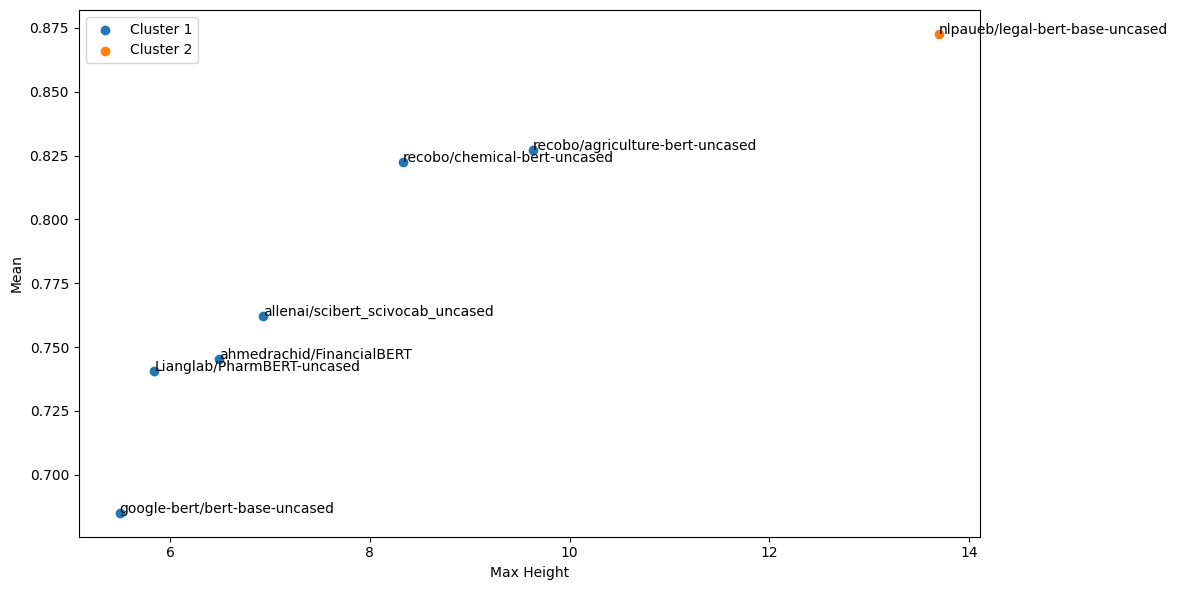

Cluster 1: more-fit
Cluster 2: less-fit
Models in the more-fit cluster: [0, 1, 3, 4, 5, 6]
Elapsed time: 1.14 seconds
0.01034 gCO2eq


([0, 1, 3, 4, 5, 6], [2])

In [6]:
result_sizes = lmdfitAgus0.running_sizes(
    csv_file=csv_file,
    sizes=[sample_size],
    x_column=text_column,
    num_repetitions=num_repeat,
    num_quantiles=group_size,
    max_token=True,
    sentence_padding=True,
    models=lmdfitAgus0.models,
    batch_size=64
)

lmdfitAgus0.display_lmdfit(
    result_sizes,
    mynumber=sample_size
)